# Teacher Integration Intention: Exploratory Machine Learning

## Objective

Predict teachers’ reported intention to integrate computational thinking
using five survey characteristics.

The target is grouped into:

- **0 — Lower/moderate intention:** original ratings of 1–3.
- **1 — Higher intention:** original ratings of 4–5.

Three models will be compared:

1. Dummy Classifier: majority-class baseline.
2. Logistic Regression: regularized classification model.
3. Shallow Decision Tree: a limited-depth comparison model.

This analysis uses responses collected at the same time. It does not predict
verified future classroom implementation or measure the effect of the summit.

Because the dataset is small, all results are exploratory.

In [1]:

%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import re
import unicodedata

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay,
)

current = Path.cwd().resolve()

ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / "data" / "cleaned").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Cannot locate your data/cleaned folder.")

DATA_PATH = (
    ROOT / "data" / "cleaned"
    / "teachers_pre_event_standardized.xlsx"
)

TABLES = ROOT / "outputs" / "tables" / "teacher_models"
FIGURES = ROOT / "outputs" / "figures" / "teacher_models"
MODELS = ROOT / "outputs" / "models"

for folder in [TABLES, FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Run the export cell in 03_teachers_analysis.ipynb first."
    )

SEED = 42
PURPLE = "#6F42A6"
ORANGE = "#E8913A"

LABELS = {
    0: "Lower/moderate intention",
    1: "Higher intention",
}

FEATURES = [
    "teaching_experience",
    "familiarity_ct",
    "familiarity_matatag",
    "project_facilitation",
    "usage_ai",
]

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

df = pd.read_excel(
    DATA_PATH,
    sheet_name="Standardized Data",
    keep_default_na=False,
    na_values=[""],
)

required = [
    "response_id",
    "school_name",
    "possible_duplicate",
    "integration_intention",
    *FEATURES,
]

missing_columns = sorted(set(required) - set(df.columns))

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

assert df["response_id"].notna().all()
assert df["response_id"].is_unique

print("Loaded submissions:", len(df))
print("scikit-learn version:", sklearn.__version__)
display(df[["response_id", *FEATURES, "integration_intention"]].head())

Loaded submissions: 55
scikit-learn version: 1.9.0


,response_id,teaching_experience,familiarity_ct,familiarity_matatag,project_facilitation,usage_ai,integration_intention
0,T0001,4–7 years,Slightly familiar,Slightly familiar,No,Never used,1
1,T0002,More than 15 years,Familiar,Familiar,No,Used personally,4
2,T0003,1–3 years,Not familiar,Not familiar,No,Never used,5
3,T0004,More than 15 years,Somewhat familiar,Somewhat familiar,No,Used personally,4
4,T0005,More than 15 years,Somewhat familiar,Somewhat familiar,No,Used personally,4


## 1. Prepare the Modeling Sample

For this initial exploratory run, all unresolved duplicate-candidate rows
are temporarily excluded. This does not establish that they are actual
duplicates; it avoids arbitrarily choosing which submission to retain.

Submissions without a school name are excluded because their school group
cannot be established for validation. Missing or inconsistent cluster
numbers alone do not require exclusion: grouping uses the school name.

Submissions with missing target responses are also excluded. Missing
predictor responses will be handled inside each training fold.

The original spreadsheet remains unchanged. Exclusion reasons are recorded
so that the analysis can be repeated after data-quality review.

In [3]:
def normalize_text(value):
    if pd.isna(value):
        return np.nan

    text = unicodedata.normalize("NFKC", str(value))
    text = re.sub(r"\s+", " ", text).strip()
    return text if text else np.nan


# Safely parse flags imported from Excel.
flag_text = (
    df["possible_duplicate"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

flag_lookup = {
    "true": True,
    "false": False,
    "1": True,
    "0": False,
    "1.0": True,
    "0.0": False,
}

bad_flags = flag_text.isna() | ~flag_text.isin(flag_lookup)

if bad_flags.any():
    raise ValueError("Review missing or unexpected possible_duplicate flags.")

duplicate_flag = flag_text.map(flag_lookup).astype(bool)

# Use school names, not clusters, as validation groups.
df["school_group"] = (
    df["school_name"]
    .map(normalize_text)
    .astype("string")
    .str.casefold()
)

target_original = df["integration_intention"].map(normalize_text)
target_rating = pd.to_numeric(target_original, errors="coerce")

invalid_target = (
    target_original.notna()
    & ~target_rating.isin([1, 2, 3, 4, 5])
)

if invalid_target.any():
    display(df.loc[
        invalid_target,
        ["response_id", "integration_intention"]
    ])
    raise ValueError("Unexpected target ratings; review before continuing.")

reasons = pd.DataFrame({
    "unresolved_duplicate_candidate": duplicate_flag,
    "missing_school_name": df["school_group"].isna(),
    "missing_target": target_rating.isna(),
})

excluded_mask = reasons.any(axis=1)

exclusion_audit = df[["response_id"]].copy()
exclusion_audit["excluded"] = excluded_mask
exclusion_audit["reason"] = reasons.apply(
    lambda row: "; ".join(row.index[row.to_numpy(dtype=bool)]),
    axis=1,
)

model_df = df.loc[~excluded_mask].copy()

model_df["target_rating"] = (
    target_rating.loc[model_df.index].astype(int)
)
model_df["target"] = (
    model_df["target_rating"].ge(4).astype(int)
)

model_df = model_df.reset_index(drop=True)

sample_summary = pd.DataFrame({
    "item": [
        "Loaded submissions",
        "Excluded submissions (unique rows)",
        "Retained modeling submissions",
        "School groups retained",
    ],
    "count": [
        len(df),
        int(excluded_mask.sum()),
        len(model_df),
        model_df["school_group"].nunique(),
    ],
})

display(sample_summary)
display(exclusion_audit.loc[exclusion_audit["excluded"]])

if model_df["target"].nunique() != 2:
    raise ValueError("Both target classes are required for classification.")

,item,count
0,Loaded submissions,55
1,Excluded submissions (unique rows),5
2,Retained modeling submissions,50
3,School groups retained,37


,response_id,excluded,reason
0,T0001,True,missing_school_name
34,T0035,True,unresolved_duplicate_candidate
36,T0037,True,unresolved_duplicate_candidate
37,T0038,True,missing_school_name
53,T0054,True,missing_school_name


## 2. Target Distribution After Exclusions

Recalculate the target distribution using only the retained modeling sample.

The majority-class percentage provides a descriptive accuracy reference.
During validation, however, the Dummy Classifier learns the majority class
separately from each training fold.

The two target groups represent reported intention. Lower/moderate ratings
should not be interpreted as unwillingness to integrate computational thinking.

,target,group,count,percent
0,0,Lower/moderate intention,19,38.0
1,1,Higher intention,31,62.0


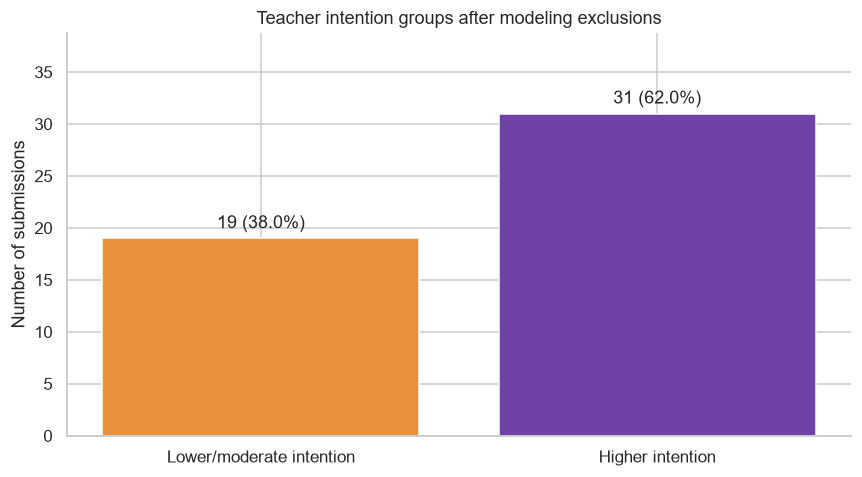

Full modeling-sample majority-class percentage: 62.0%


In [4]:
target_counts = (
    model_df["target"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

target_table = pd.DataFrame({
    "target": [0, 1],
    "group": [LABELS[0], LABELS[1]],
    "count": target_counts.to_numpy(),
})

target_table["percent"] = (
    target_table["count"] / len(model_df) * 100
).round(1)

display(target_table)

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    target_table["group"],
    target_table["count"],
    color=[ORANGE, PURPLE],
)

ax.bar_label(
    bars,
    labels=[
        f"{row.count} ({row.percent:.1f}%)"
        for row in target_table.itertuples()
    ],
    padding=4,
)

ax.set(
    title="Teacher intention groups after modeling exclusions",
    ylabel="Number of submissions",
    ylim=(0, target_table["count"].max() * 1.25),
)

fig.tight_layout()
fig.savefig(FIGURES / "01_target_distribution.png", bbox_inches="tight")
plt.show()

print(
    "Full modeling-sample majority-class percentage:",
    f"{target_counts.max() / target_counts.sum():.1%}",
)

## 3. Predictors and Preprocessing

Five predictors are selected before comparing model performance:

- Teaching experience.
- Familiarity with computational thinking.
- Familiarity with MATATAG CT competencies.
- Previous project facilitation.
- Reported AI use.

All five are treated as categorical variables. One-hot encoding avoids
assuming equally spaced differences between survey categories.

Missing answers are represented by a separate category. The preprocessing
pipeline is fitted separately inside each training fold.

Names, response IDs, school identifiers, target-derived variables,
unreviewed text, and the questions with uncertain post-summit confidence
wording are excluded from the predictors.

In [5]:
X = model_df[FEATURES].copy()

for column in FEATURES:
    X[column] = X[column].map(normalize_text)
    # Ensure missing entries are np.nan rather than pd.NA.
    X[column] = X[column].astype(object)
    X[column] = X[column].where(X[column].notna(), np.nan)

y = model_df["target"].astype(int)
groups = model_df["school_group"].astype(str)

feature_summary = pd.DataFrame({
    "feature": FEATURES,
    "missing_count": X.isna().sum().to_numpy(),
    "observed_categories": [
        X[column].nunique(dropna=True) for column in FEATURES
    ],
})

display(feature_summary)

for column in FEATURES:
    print(f"\n{column}:")
    print(sorted(X[column].dropna().unique()))


def make_preprocessor():
    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing response",
                keep_empty_features=True,
            ),
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ])

,feature,missing_count,observed_categories
0,teaching_experience,0,4
1,familiarity_ct,0,4
2,familiarity_matatag,0,5
3,project_facilitation,0,2
4,usage_ai,0,3



teaching_experience:
['1–3 years', '4–7 years', '8–15 years', 'More than 15 years']

familiarity_ct:
['Familiar', 'Not familiar', 'Slightly familiar', 'Somewhat familiar']

familiarity_matatag:
['Familiar', 'Not familiar', 'Slightly familiar', 'Somewhat familiar', 'Very familiar']

project_facilitation:
['No', 'Yes']

usage_ai:
['Never used', 'Used personally', 'Used with students']


## 4. School-Grouped Cross-Validation

Respondents from the same school must remain together within each
validation split. This evaluates prediction for respondents from schools
absent from the corresponding training data.

The initial plan uses three folds with a fixed random seed. If this does
not provide both target classes in every training and validation set,
a predefined two-fold fallback is checked.

The choice of split depends only on group and class feasibility, not on
model performance. All models use exactly the same splits.

In [6]:
splits = None

# Predefined fallback; no search for a favorable model score.
for n_splits in [3, 2]:
    if groups.nunique() < n_splits:
        continue

    if y.value_counts().min() < n_splits:
        continue

    splitter = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=SEED,
    )

    candidate_splits = list(splitter.split(X, y, groups))

    valid = all(
        y.iloc[train_idx].nunique() == 2
        and y.iloc[test_idx].nunique() == 2
        and set(groups.iloc[train_idx]).isdisjoint(
            set(groups.iloc[test_idx])
        )
        for train_idx, test_idx in candidate_splits
    )

    if valid:
        splits = candidate_splits
        break

if splits is None:
    raise ValueError(
        "Cannot form suitable grouped folds with this fixed setup. "
        "Review school groups and class counts before modeling."
    )

fold_rows = []
fold_assignment = np.zeros(len(X), dtype=int)
test_visits = np.zeros(len(X), dtype=int)

for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    fold_assignment[test_idx] = fold
    test_visits[test_idx] += 1

    fold_rows.append({
        "fold": fold,
        "train_n": len(train_idx),
        "validation_n": len(test_idx),
        "train_schools": groups.iloc[train_idx].nunique(),
        "validation_schools": groups.iloc[test_idx].nunique(),
        "train_class_0": int((y.iloc[train_idx] == 0).sum()),
        "train_class_1": int((y.iloc[train_idx] == 1).sum()),
        "validation_class_0": int((y.iloc[test_idx] == 0).sum()),
        "validation_class_1": int((y.iloc[test_idx] == 1).sum()),
    })

assert np.all(test_visits == 1)

fold_table = pd.DataFrame(fold_rows)
display(fold_table)

print("Number of validation folds:", len(splits))

,fold,train_n,validation_n,train_schools,validation_schools,train_class_0,train_class_1,validation_class_0,validation_class_1
0,1,33,17,25,12,13,20,6,11
1,2,34,16,24,13,13,21,6,10
2,3,33,17,25,12,12,21,7,10


Number of validation folds: 3


## 5. Model Training and Evaluation

The models use fixed settings, with no hyperparameter tuning:

- **Dummy Classifier:** always predicts the most common training class.
- **Logistic Regression:** regularized, with balanced class weights.
- **Decision Tree:** maximum depth of 2 and at least 5 training
  submissions per leaf, with balanced class weights.

Balanced class weights increase the contribution of the less frequent
class during training; they do not create additional observations.

Evaluation includes balanced accuracy, macro F1, accuracy, and recall
for each class. Balanced accuracy and macro F1 receive particular attention
because overall accuracy can hide poor performance on one group.

Each retained submission receives one out-of-fold prediction from a model
trained without that submission or its school.

In [7]:
estimators = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=SEED,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=SEED,
    ),
}

pipelines = {
    name: Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", estimator),
    ])
    for name, estimator in estimators.items()
}


def calculate_metrics(actual, predicted):
    return {
        "accuracy": accuracy_score(actual, predicted),
        "balanced_accuracy": balanced_accuracy_score(actual, predicted),
        "macro_f1": f1_score(
            actual, predicted,
            labels=[0, 1],
            average="macro",
            zero_division=0,
        ),
        "recall_0": recall_score(
            actual, predicted, pos_label=0, zero_division=0
        ),
        "recall_1": recall_score(
            actual, predicted, pos_label=1, zero_division=0
        ),
    }


fold_results = []
oof_predictions = {}
report_tables = {}

for name, pipeline in pipelines.items():
    predicted = np.full(len(X), -1, dtype=int)

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        fitted = clone(pipeline)

        fitted.fit(X.iloc[train_idx], y.iloc[train_idx])
        fold_pred = fitted.predict(X.iloc[test_idx])

        predicted[test_idx] = fold_pred

        fold_results.append({
            "model": name,
            "fold": fold,
            **calculate_metrics(y.iloc[test_idx], fold_pred),
        })

    assert np.all(predicted != -1)
    oof_predictions[name] = predicted

    report_tables[name] = (
        pd.DataFrame(
            classification_report(
                y,
                predicted,
                labels=[0, 1],
                target_names=[LABELS[0], LABELS[1]],
                output_dict=True,
                zero_division=0,
            )
        )
        .transpose()
        .rename_axis("class_or_metric")
        .reset_index()
    )

fold_scores = pd.DataFrame(fold_results)

metrics = [
    "balanced_accuracy",
    "macro_f1",
    "accuracy",
    "recall_0",
    "recall_1",
]

cv_summary = (
    fold_scores.groupby("model")[metrics]
    .agg(["mean", "std"])
)

cv_summary.columns = [
    f"{metric}_{stat}" for metric, stat in cv_summary.columns
]

cv_summary = cv_summary.reset_index()

pooled_scores = pd.DataFrame([
    {
        "model": name,
        **calculate_metrics(y, predicted),
    }
    for name, predicted in oof_predictions.items()
])

print("Mean and standard deviation across validation folds:")
display(cv_summary.round(3))

print("Metrics calculated from all out-of-fold predictions together:")
display(pooled_scores.round(3))

Mean and standard deviation across validation folds:


,model,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,recall_0_mean,recall_0_std,recall_1_mean,recall_1_std
0,Baseline,0.500,0.000,0.383,0.011,0.620,0.030,0.000,0.000,1.000,0.000
1,Decision Tree,0.697,0.133,0.678,0.128,0.701,0.098,0.651,0.316,0.742,0.052
2,Logistic Regression,0.700,0.066,0.690,0.055,0.701,0.052,0.690,0.133,0.709,0.016


Metrics calculated from all out-of-fold predictions together:


,model,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1
0,Baseline,0.62,0.500,0.383,0.000,1.000
1,Logistic Regression,0.70,0.697,0.690,0.684,0.710
2,Decision Tree,0.70,0.687,0.685,0.632,0.742


## 6. Model Performance Figures

The comparison chart shows mean validation scores. Error bars indicate
standard deviation across folds, not confidence intervals.

Confusion matrices show pooled out-of-fold predictions. Rows represent
actual classes and columns represent predicted classes.

A useful model must be assessed against the baseline and must be examined
for its ability to recognize both intention groups. A higher score from
this small evaluation alone does not establish reliable generalization.

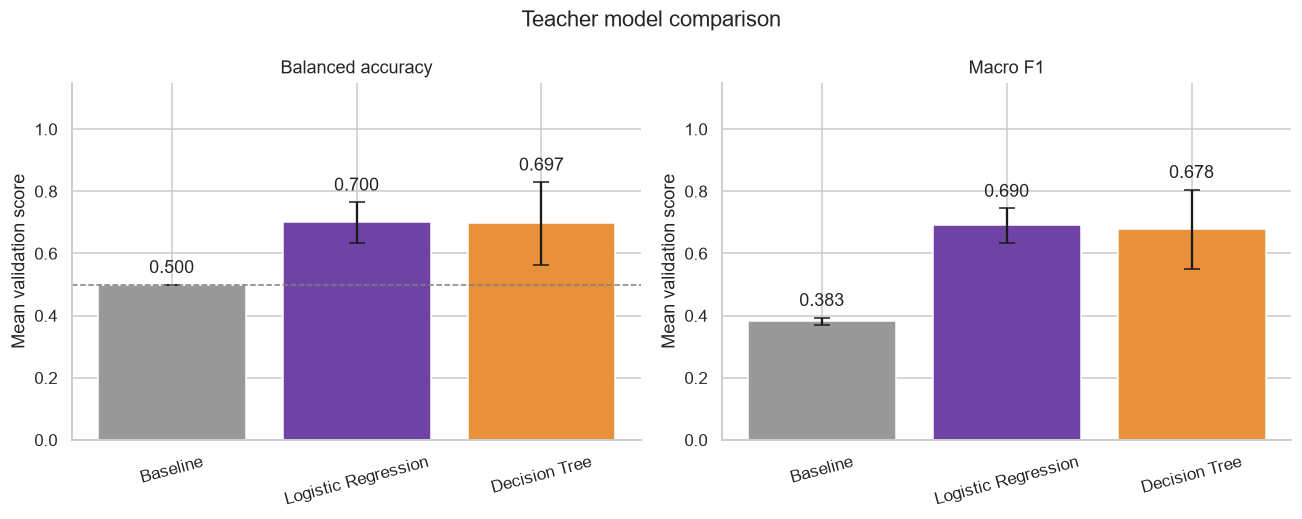

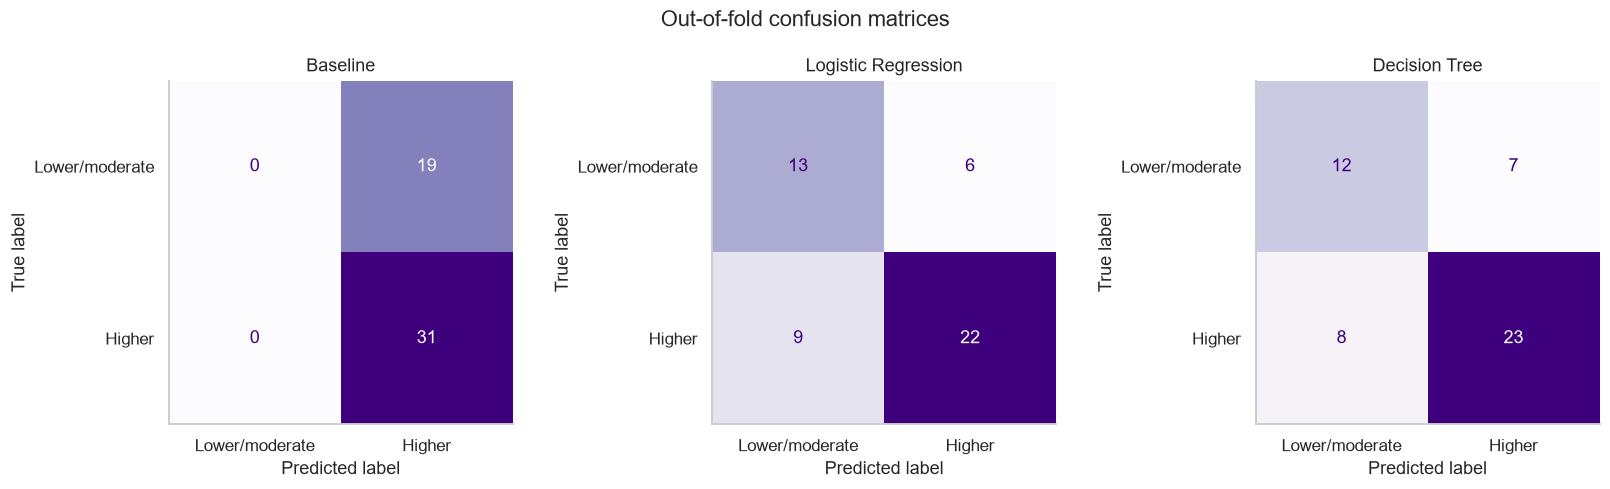


Baseline


,class_or_metric,precision,recall,f1-score,support
0,Lower/moderate intention,0.000,0.00,0.000,19.00
1,Higher intention,0.620,1.00,0.765,31.00
2,accuracy,0.620,0.62,0.620,0.62
3,macro avg,0.310,0.50,0.383,50.00
4,weighted avg,0.384,0.62,0.475,50.00



Logistic Regression


,class_or_metric,precision,recall,f1-score,support
0,Lower/moderate intention,0.591,0.684,0.634,19.0
1,Higher intention,0.786,0.710,0.746,31.0
2,accuracy,0.700,0.700,0.700,0.7
3,macro avg,0.688,0.697,0.690,50.0
4,weighted avg,0.712,0.700,0.703,50.0



Decision Tree


,class_or_metric,precision,recall,f1-score,support
0,Lower/moderate intention,0.600,0.632,0.615,19.0
1,Higher intention,0.767,0.742,0.754,31.0
2,accuracy,0.700,0.700,0.700,0.7
3,macro avg,0.683,0.687,0.685,50.0
4,weighted avg,0.703,0.700,0.701,50.0


In [8]:
model_order = list(pipelines)
plot_data = cv_summary.set_index("model").loc[model_order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for ax, metric, title in zip(
    axes,
    ["balanced_accuracy", "macro_f1"],
    ["Balanced accuracy", "Macro F1"],
):
    means = plot_data[f"{metric}_mean"]
    stds = plot_data[f"{metric}_std"].fillna(0)

    bars = ax.bar(
        model_order,
        means,
        yerr=stds,
        capsize=5,
        color=["#999999", PURPLE, ORANGE],
    )

    ax.bar_label(bars, fmt="%.3f", padding=5)
    ax.set_title(title)
    ax.set_ylabel("Mean validation score")
    ax.set_ylim(0, 1.15)
    ax.tick_params(axis="x", rotation=15)

    if metric == "balanced_accuracy":
        ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)

fig.suptitle("Teacher model comparison")
fig.tight_layout()
fig.savefig(FIGURES / "02_model_comparison.png", bbox_inches="tight")
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, name in zip(axes, model_order):
    ConfusionMatrixDisplay.from_predictions(
        y,
        oof_predictions[name],
        labels=[0, 1],
        display_labels=["Lower/moderate", "Higher"],
        cmap="Purples",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)
    ax.grid(False)

fig.suptitle("Out-of-fold confusion matrices")
fig.tight_layout()
fig.savefig(FIGURES / "03_confusion_matrices.png", bbox_inches="tight")
plt.show()

for name, report in report_tables.items():
    print(f"\n{name}")
    display(report.round(3))

## 7. Actual Versus Predicted Intention

This table contains held-out predictions for every retained submission.

Each prediction was generated without using that respondent’s school
during model training. These predictions are used for evaluation.

Response IDs are retained for internal traceability. Names are excluded
from this output.

In [9]:
prediction_table = model_df[
    ["response_id", "target_rating"]
].copy()

prediction_table["validation_fold"] = fold_assignment
prediction_table["actual_class"] = y.to_numpy()
prediction_table["actual_group"] = y.map(LABELS).to_numpy()

prediction_columns = {
    "Baseline": "baseline",
    "Logistic Regression": "logistic",
    "Decision Tree": "tree",
}

for name, prefix in prediction_columns.items():
    predicted = oof_predictions[name]

    prediction_table[f"{prefix}_class"] = predicted
    prediction_table[f"{prefix}_group"] = (
        pd.Series(predicted).map(LABELS).to_numpy()
    )
    prediction_table[f"{prefix}_correct"] = predicted == y.to_numpy()

display(prediction_table.head(15))

print("Logistic Regression errors:")
display(
    prediction_table.loc[
        ~prediction_table["logistic_correct"],
        [
            "response_id",
            "target_rating",
            "actual_group",
            "logistic_group",
            "validation_fold",
        ],
    ]
)

,response_id,target_rating,validation_fold,actual_class,actual_group,baseline_class,baseline_group,baseline_correct,logistic_class,logistic_group,logistic_correct,tree_class,tree_group,tree_correct
0,T0002,4,1,1,Higher intention,1,Higher intention,True,1,Higher intention,True,1,Higher intention,True
1,T0003,5,2,1,Higher intention,1,Higher intention,True,0,Lower/moderate intention,False,0,Lower/moderate intention,False
2,T0004,4,1,1,Higher intention,1,Higher intention,True,1,Higher intention,True,1,Higher intention,True
3,T0005,4,2,1,Higher intention,1,Higher intention,True,1,Higher intention,True,1,Higher intention,True
4,T0006,4,1,1,Higher intention,1,Higher intention,True,1,Higher intention,True,1,Higher intention,True
5,T0007,3,2,0,Lower/moderate intention,1,Higher intention,False,1,Higher intention,False,1,Higher intention,False
6,T0008,1,1,0,Lower/moderate intention,1,Higher intention,False,0,Lower/moderate intention,True,0,Lower/moderate intention,True
7,T0009,4,3,1,Higher intention,1,Higher intention,True,0,Lower/moderate intention,False,0,Lower/moderate intention,False
8,T0010,5,3,1,Higher intention,1,Higher intention,True,1,Higher intention,True,1,Higher intention,True
9,T0011,3,1,0,Lower/moderate intention,1,Higher intention,False,0,Lower/moderate intention,True,0,Lower/moderate intention,True


Logistic Regression errors:


,response_id,target_rating,actual_group,logistic_group,validation_fold
1,T0003,5,Higher intention,Lower/moderate intention,2
5,T0007,3,Lower/moderate intention,Higher intention,2
7,T0009,4,Higher intention,Lower/moderate intention,3
11,T0013,5,Higher intention,Lower/moderate intention,3
15,T0017,3,Lower/moderate intention,Higher intention,1
16,T0018,1,Lower/moderate intention,Higher intention,3
19,T0021,4,Higher intention,Lower/moderate intention,3
22,T0024,4,Higher intention,Lower/moderate intention,1
26,T0028,5,Higher intention,Lower/moderate intention,1
30,T0032,4,Higher intention,Lower/moderate intention,2


## 8. Reference Models for Demonstration

After evaluation, Logistic Regression and the Decision Tree are fitted
on the full retained modeling sample.

Logistic Regression is retained as the preselected reference model,
regardless of which model obtains the highest validation score.
Saving this model does not establish that it is suitable for deployment.

The tree diagram describes the full-sample fitted tree. It is an
illustration of learned rules, not an additional validation result.
Its weighted class counts reflect the use of balanced class weights.

Predictions for new profiles remain exploratory. They should not be
interpreted as verified future behavior.

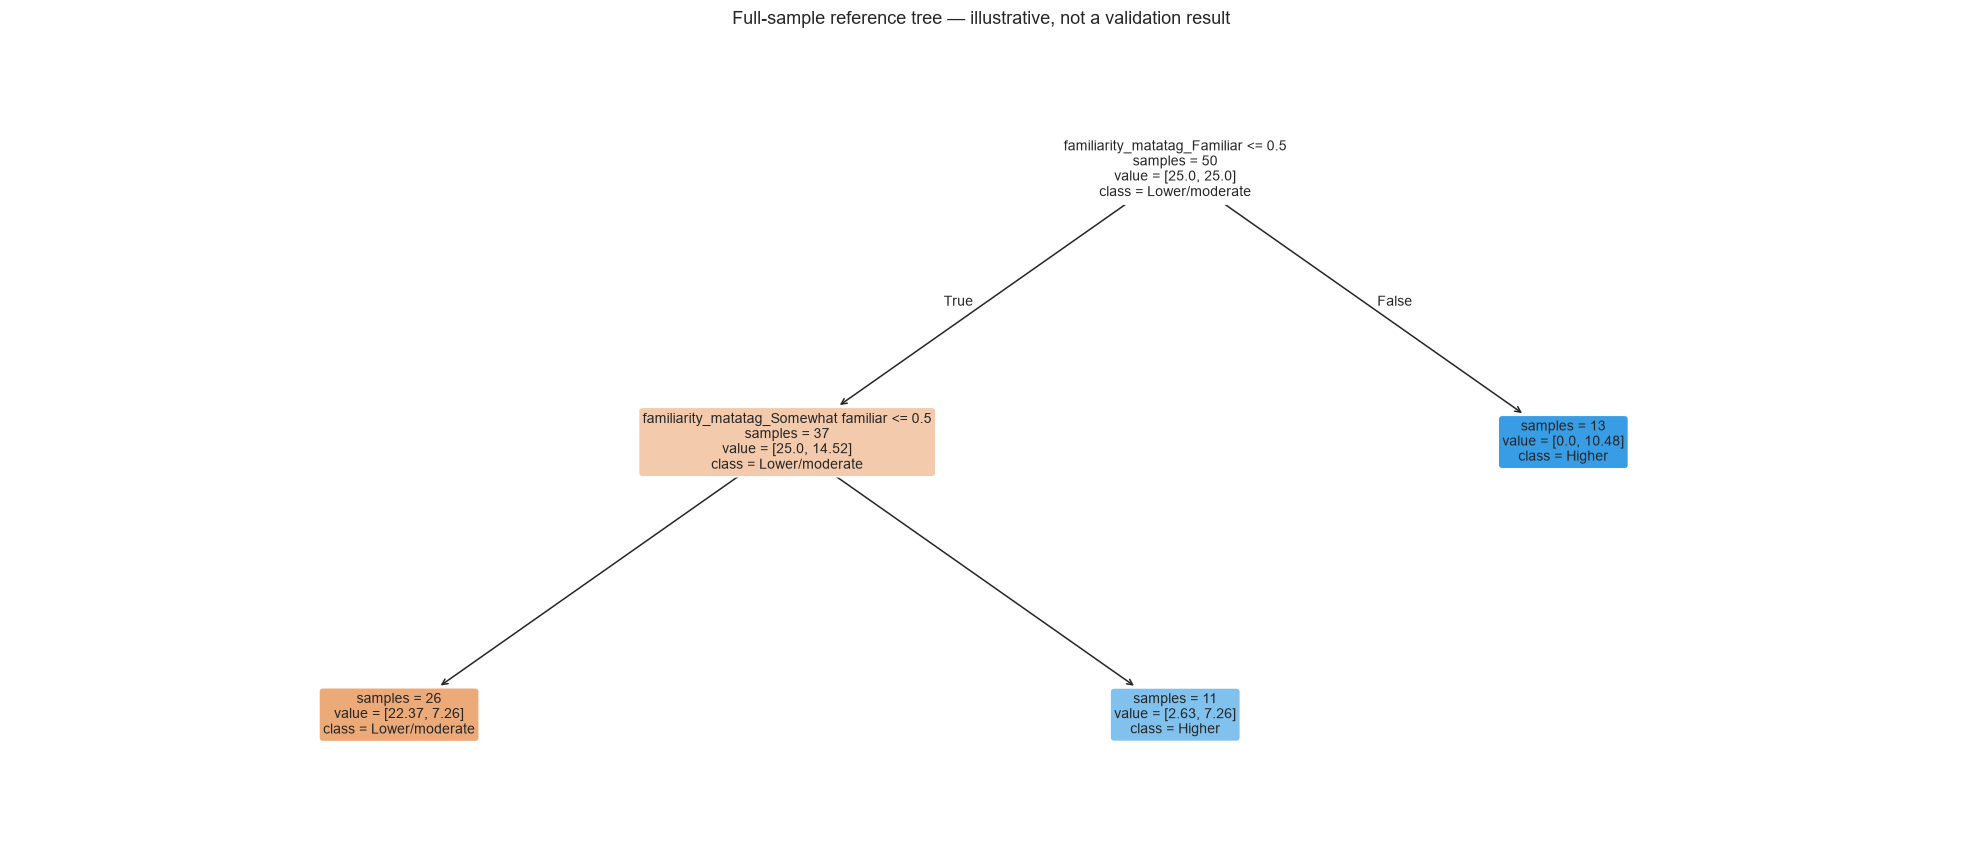

Saved reference model: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\models\teachers_logistic_exploratory.joblib


In [10]:
reference_model = clone(pipelines["Logistic Regression"]).fit(X, y)
reference_tree = clone(pipelines["Decision Tree"]).fit(X, y)

encoded_names = (
    reference_tree.named_steps["preprocess"]
    .named_steps["encoder"]
    .get_feature_names_out(FEATURES)
)

fig, ax = plt.subplots(figsize=(18, 8))

plot_tree(
    reference_tree.named_steps["model"],
    feature_names=encoded_names,
    class_names=["Lower/moderate", "Higher"],
    filled=True,
    rounded=True,
    impurity=False,
    precision=2,
    fontsize=9,
    ax=ax,
)

ax.set_title(
    "Full-sample reference tree — illustrative, not a validation result"
)

fig.tight_layout()
fig.savefig(
    FIGURES / "04_reference_decision_tree.png",
    bbox_inches="tight",
)
plt.show()

model_bundle = {
    "pipeline": reference_model,
    "features": FEATURES,
    "labels": LABELS,
    "training_n": len(X),
    "school_groups": groups.nunique(),
    "validation_folds": len(splits),
    "random_seed": SEED,
    "sklearn_version": sklearn.__version__,
    "target_definition": "0: ratings 1–3; 1: ratings 4–5",
    "purpose": "Exploratory same-survey intention classification",
}

model_path = MODELS / "teachers_logistic_exploratory.joblib"
joblib.dump(model_bundle, model_path)

print("Saved reference model:", model_path)

### Demonstration Prediction for a Hypothetical Profile

The following example is hypothetical and is not an additional survey
respondent. It demonstrates how to apply the saved reference model.

Use category labels exactly as displayed in the predictor summary.
This example does not contribute to model evaluation.

In [11]:
# Hypothetical example only.
# The experience category below is taken from an observed category
# so its spelling matches your spreadsheet.
example_profile = pd.DataFrame([{
    "teaching_experience": X["teaching_experience"].dropna().mode().iloc[0],
    "familiarity_ct": "Somewhat familiar",
    "familiarity_matatag": "Slightly familiar",
    "project_facilitation": "No",
    "usage_ai": "Used personally",
}])

saved_bundle = joblib.load(model_path)

example_prediction = saved_bundle["pipeline"].predict(
    example_profile[saved_bundle["features"]]
)

example_result = example_profile.copy()
example_result["predicted_group"] = [
    LABELS[int(value)] for value in example_prediction
]

display(example_result)

print(
    "This is an exploratory prediction for a hypothetical profile, "
    "not evidence of future classroom implementation."
)

,teaching_experience,familiarity_ct,familiarity_matatag,project_facilitation,usage_ai,predicted_group
0,8–15 years,Somewhat familiar,Slightly familiar,No,Used personally,Higher intention


This is an exploratory prediction for a hypothetical profile, not evidence of future classroom implementation.


## 9. Export Results

Export the sample audit, target distribution, validation splits,
model scores, classification reports, and held-out predictions
to one formatted Excel workbook.

Figures are saved separately as PNG files. The reference model is saved
as a joblib file for reproducible demonstration.

The prediction workbook contains response IDs for internal review.

In [12]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

export_tables = {
    "sample_summary": sample_summary,
    "exclusion_audit": exclusion_audit,
    "target_distribution": target_table,
    "feature_summary": feature_summary,
    "validation_folds": fold_table,
    "fold_scores": fold_scores,
    "cv_summary": cv_summary,
    "pooled_oof_scores": pooled_scores,
    "held_out_predictions": prediction_table,
    "hypothetical_example": example_result,
}

for name, prefix in prediction_columns.items():
    export_tables[f"{prefix}_report"] = report_tables[name]

export_tables["model_notes"] = pd.DataFrame([
    {
        "item": "Target",
        "details": "Reported intention: ratings 1–3 versus 4–5.",
    },
    {
        "item": "Validation",
        "details": (
            f"{len(splits)} school-grouped folds; fixed seed {SEED}; "
            "same splits for all models."
        ),
    },
    {
        "item": "Exclusions",
        "details": (
            "Unresolved duplicate candidates, missing school names, "
            "and missing target responses."
        ),
    },
    {
        "item": "Interpretation",
        "details": (
            "Exploratory same-survey classification; "
            "not a forecast of actual implementation."
        ),
    },
    {
        "item": "Software",
        "details": f"scikit-learn {sklearn.__version__}",
    },
])

workbook_path = TABLES / "teachers_prediction_results.xlsx"

with pd.ExcelWriter(workbook_path, engine="openpyxl") as writer:
    for sheet_name, table in export_tables.items():
        table.to_excel(writer, sheet_name=sheet_name[:31], index=False)

    for ws in writer.book.worksheets:
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        ws.sheet_view.showGridLines = False
        ws.row_dimensions[1].height = 42

        for cell in ws[1]:
            cell.fill = PatternFill("solid", fgColor="4C286B")
            cell.font = Font(bold=True, color="FFFFFF")
            cell.alignment = Alignment(
                wrap_text=True, vertical="center"
            )

        for column_index in range(1, ws.max_column + 1):
            values = [
                "" if cell.value is None else str(cell.value)
                for cell in ws[get_column_letter(column_index)]
            ]

            ws.column_dimensions[
                get_column_letter(column_index)
            ].width = min(48, max(16, max(map(len, values)) + 2))

        for row in ws.iter_rows(min_row=2):
            for cell in row:
                cell.alignment = Alignment(
                    wrap_text=True, vertical="top"
                )

                if isinstance(cell.value, float):
                    cell.number_format = "0.000"

                if isinstance(cell.value, str) and cell.value.startswith("="):
                    cell.data_type = "s"

print("Excel results:", workbook_path)
print("Figures:", FIGURES)
print("Reference model:", model_path)

Excel results: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\tables\teacher_models\teachers_prediction_results.xlsx
Figures: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\figures\teacher_models
Reference model: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\models\teachers_logistic_exploratory.joblib


## 10. Findings and Limitations

The summary below is generated from the actual validation results.
Scores are reported on a 0–1 scale.

Mean fold scores and pooled out-of-fold scores are different summaries
and may not be identical. Standard deviations across a few folds should
not be treated as confidence intervals.

Interpretation must consider baseline performance, recall for both
groups, the small sample, and the provisional exclusion decisions.

In [13]:
summary_index = cv_summary.set_index("model")
pooled_index = pooled_scores.set_index("model")

baseline_ba = summary_index.loc[
    "Baseline", "balanced_accuracy_mean"
]

paragraphs = [
    "### Exploratory Model Findings",
    (
        f"The modeling sample contained **{len(model_df)} submissions "
        f"from {groups.nunique()} school groups**, after excluding "
        f"{int(excluded_mask.sum())} submissions. Evaluation used "
        f"**{len(splits)} school-grouped validation folds**."
    ),
]

for name in model_order:
    row = summary_index.loc[name]

    paragraphs.append(
        f"**{name}:** mean balanced accuracy "
        f"**{row['balanced_accuracy_mean']:.3f}** "
        f"(fold SD {row['balanced_accuracy_std']:.3f}) and mean "
        f"macro F1 **{row['macro_f1_mean']:.3f}**."
    )

for name in ["Logistic Regression", "Decision Tree"]:
    difference = (
        summary_index.loc[name, "balanced_accuracy_mean"]
        - baseline_ba
    )

    if difference > 0:
        comparison = (
            f"exceeded the baseline mean balanced accuracy by "
            f"{difference:.3f} in this evaluation"
        )
    elif difference < 0:
        comparison = (
            f"fell below the baseline mean balanced accuracy by "
            f"{abs(difference):.3f} in this evaluation"
        )
    else:
        comparison = "matched the baseline mean balanced accuracy"

    paragraphs.append(
        f"{name} {comparison}. This comparison alone does not "
        "establish a reliable performance advantage."
    )

lr = pooled_index.loc["Logistic Regression"]

paragraphs.append(
    "For Logistic Regression, pooled out-of-fold recall was "
    f"**{lr['recall_0']:.1%}** for lower/moderate intention and "
    f"**{lr['recall_1']:.1%}** for higher intention. These values "
    "show how successfully the model recognized each group."
)

paragraphs.append(
    "The results describe exploratory prediction of self-reported "
    "intention from other responses in the same survey. They do not "
    "demonstrate actual classroom implementation, causal relationships, "
    "or summit effectiveness. The small sample and provisional "
    "exclusions limit generalization. A larger independent sample "
    "would be needed to assess whether the observed performance persists."
)

display(Markdown("\n\n".join(paragraphs)))

### Exploratory Model Findings

The modeling sample contained **50 submissions from 37 school groups**, after excluding 5 submissions. Evaluation used **3 school-grouped validation folds**.

**Baseline:** mean balanced accuracy **0.500** (fold SD 0.000) and mean macro F1 **0.383**.

**Logistic Regression:** mean balanced accuracy **0.700** (fold SD 0.066) and mean macro F1 **0.690**.

**Decision Tree:** mean balanced accuracy **0.697** (fold SD 0.133) and mean macro F1 **0.678**.

Logistic Regression exceeded the baseline mean balanced accuracy by 0.200 in this evaluation. This comparison alone does not establish a reliable performance advantage.

Decision Tree exceeded the baseline mean balanced accuracy by 0.197 in this evaluation. This comparison alone does not establish a reliable performance advantage.

For Logistic Regression, pooled out-of-fold recall was **68.4%** for lower/moderate intention and **71.0%** for higher intention. These values show how successfully the model recognized each group.

The results describe exploratory prediction of self-reported intention from other responses in the same survey. They do not demonstrate actual classroom implementation, causal relationships, or summit effectiveness. The small sample and provisional exclusions limit generalization. A larger independent sample would be needed to assess whether the observed performance persists.